In [1]:
import pandas as pd
#from feature_engine.discretisation import DecisionTreeDiscretiser
import matplotlib.pyplot as plt
import funciones
import pygad
import pickle
import numpy as np

In [2]:
with open('experimento5_escalabilidad_soluciones_paralelizado.pkl', 'rb') as f:
    historial_soluciones = pickle.load(f)

In [3]:

instancias_lista = sorted(historial_soluciones.keys())
promedios_tiempo = []
desviaciones_tiempo = []

for N in instancias_lista:
    # Extraemos el campo 'tiempo' de cada corrida para este N
    tiempos_ejecucion = [run['tiempo'] for run in historial_soluciones[N]]
    
    #
    promedios_tiempo.append(np.mean(tiempos_ejecucion))
    desviaciones_tiempo.append(np.std(tiempos_ejecucion))

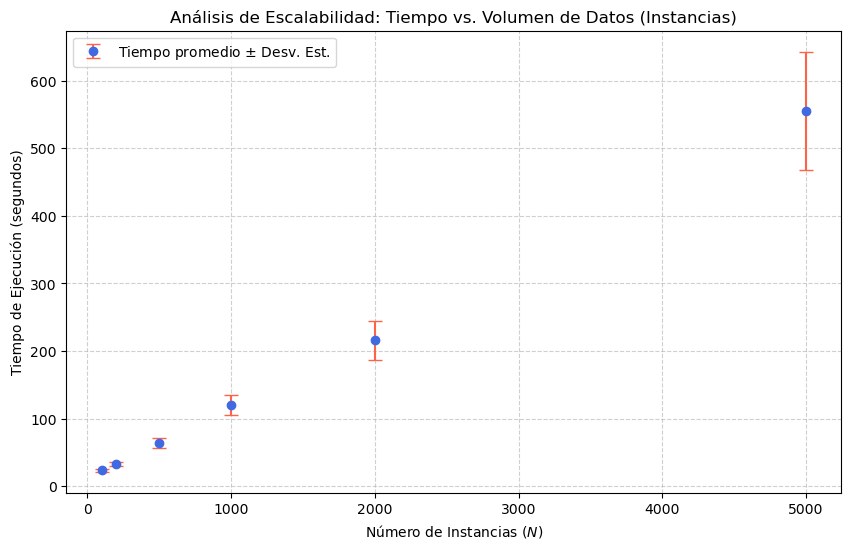

In [4]:
#complejidad empirica
plt.figure(figsize=(10, 6))

# Dibujamos los puntos con sus barras de error (Desviación Estándar)
plt.errorbar(instancias_lista, promedios_tiempo, yerr=desviaciones_tiempo, 
             fmt='o', color='royalblue', ecolor='tomato', capsize=5, 
             label='Tiempo promedio $\pm$ Desv. Est.')

plt.title('Análisis de Escalabilidad: Tiempo vs. Volumen de Datos (Instancias)')
plt.xlabel('Número de Instancias ($N$)')
plt.ylabel('Tiempo de Ejecución (segundos)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

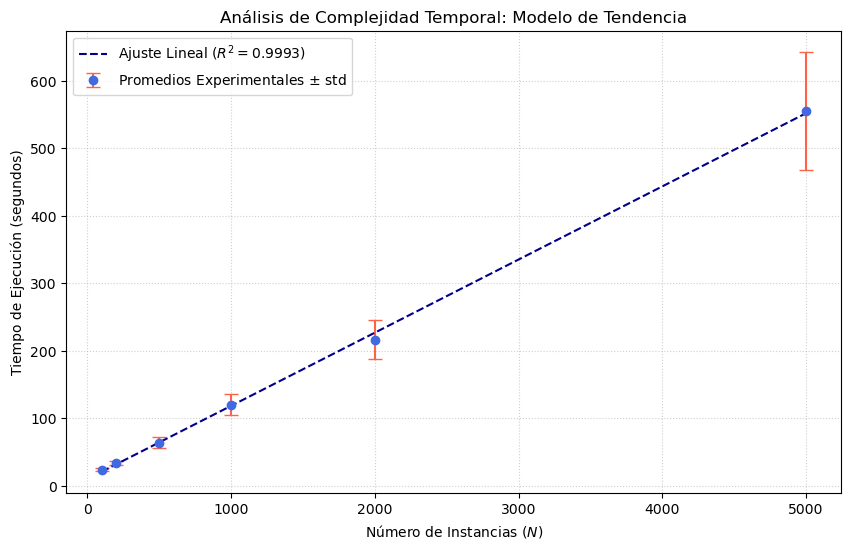

Ecuación del modelo: T(N) = 0.108449 * N + (9.5845)
Coeficiente de determinación (R²): 0.999289


In [5]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# 1. Cargar datos desde el archivo persistente
with open('experimento5_escalabilidad_soluciones_paralelizado.pkl', 'rb') as f:
    historial = pickle.load(f)

# 2. Procesar únicamente los Promedios
x_avg = sorted(historial.keys())
y_avg = []
y_std = []

for N in x_avg:
    # Extraemos todos los tiempos para el valor de N actual
    tiempos = [run['tiempo'] for run in historial[N]]
    # Calculamos el promedio y la desviación estándar según Wackerly et al.
    y_avg.append(np.mean(tiempos))
    y_std.append(np.std(tiempos))

# Convertir a arreglos de numpy para el cálculo del ajuste
x_avg = np.array(x_avg)
y_avg = np.array(y_avg)

# 3. Ajuste Lineal (Regresión sobre los centros de masa)
# El modelo busca T(N) = a*N + b
coef = np.polyfit(x_avg, y_avg, 1)
y_pred = np.polyval(coef, x_avg)
r2 = r2_score(y_avg, y_pred)

# 4. Graficación Profesional del Modelo de Tendencia
plt.figure(figsize=(10, 6))

# Puntos Experimentales: Solo promedios y barras de error (sin línea azul que los una)
plt.errorbar(x_avg, y_avg, yerr=y_std, fmt='o', color='royalblue', 
             ecolor='tomato', capsize=5, label='Promedios Experimentales $\pm$ std')

# Línea de Ajuste Lineal: El modelo teórico que describe la complejidad
x_range = np.linspace(min(x_avg), max(x_avg), 100)
plt.plot(x_range, np.polyval(coef, x_range), color='darkblue', linestyle='--', 
         label=f'Ajuste Lineal ($R^2 = {r2:.4f}$)')

plt.title('Análisis de Complejidad Temporal: Modelo de Tendencia')
plt.xlabel('Número de Instancias ($N$)')
plt.ylabel('Tiempo de Ejecución (segundos)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

# 5. Parámetros para el reporte de tesis
print(f"Ecuación del modelo: T(N) = {coef[0]:.6f} * N + ({coef[1]:.4f})")
print(f"Coeficiente de determinación (R²): {r2:.6f}")

In [6]:
#Tiempo para N instancias paralelizado
N = 100000 #Numero de instancias
tiempo= 0.108449 * (N) + 9.5845

print(f"Segundos: {tiempo}")
print(f"Minutos: {tiempo/60}")
print(f"Horas: {(tiempo/60)/60}")
print(f"Dias: {((tiempo/60)/60)/24}")

Segundos: 10854.4845
Minutos: 180.908075
Horas: 3.0151345833333334
Dias: 0.1256306076388889


In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculamos las métricas
mae = mean_absolute_error(y_avg, y_pred)
mse = mean_squared_error(y_avg, y_pred)
rmse = np.sqrt(mse)

print(f"--- Métricas de Error del Modelo ---")
print(f"MAE:  {mae:.4f} segundos")# error promedio absoluto del modelo
print(f"MSE:  {mse:.4f} segundos²")
print(f"RMSE: {rmse:.4f} segundos")

--- Métricas de Error del Modelo ---
MAE:  3.5889 segundos
MSE:  24.2492 segundos²
RMSE: 4.9244 segundos


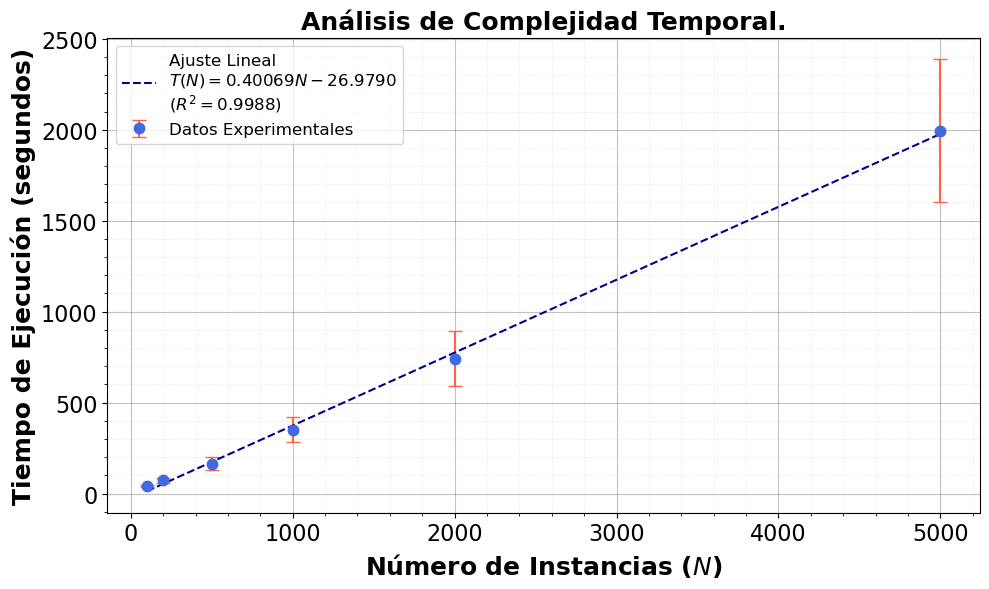

Ecuación reportada: $T(N) = 0.40069N -26.9790$


In [8]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# 1. Cargar datos
with open('experimento4_escalabilidad_soluciones.pkl', 'rb') as f:
    historial = pickle.load(f)

# 2. Procesar datos
x_avg = sorted(historial.keys())
y_avg = []
y_std = []

for N in x_avg:
    tiempos = [run['tiempo'] for run in historial[N]]
    y_avg.append(np.mean(tiempos))
    y_std.append(np.std(tiempos))

x_avg = np.array(x_avg)
y_avg = np.array(y_avg)

# 3. Ajuste Lineal
coef = np.polyfit(x_avg, y_avg, 1)
y_pred = np.polyval(coef, x_avg)
r2 = r2_score(y_avg, y_pred)

# --- CREAMOS EL TEXTO DE LA ECUACIÓN ---
# coef[0] es la pendiente (m), coef[1] es la intersección (b)
ecuacion_str = f'$T(N) = {coef[0]:.5f}N {coef[1]:+.4f}$'
label_ajuste = f'Ajuste Lineal\n{ecuacion_str}\n($R^2 = {r2:.4f}$)'

# 4. Graficación
plt.figure(figsize=(10, 6))

# Puntos Experimentales
plt.errorbar(x_avg, y_avg, yerr=y_std, fmt='o', color='royalblue', 
             ecolor='tomato', capsize=5, label='Datos Experimentales', markersize=7.5)

# Línea de Ajuste (Recta)
x_range = np.linspace(min(x_avg), max(x_avg), 100)
plt.plot(x_range, np.polyval(coef, x_range), color='darkblue', linestyle='--', 
         label=label_ajuste)  # <--- Aquí ponemos la ecuación en la leyenda

# Opcional: Si prefieres la ecuación flotando en el gráfico en lugar de la leyenda:
# plt.text(0.05, 0.85, ecuacion_str + f'\n$R^2 = {r2:.4f}$', 
#          transform=plt.gca().transAxes, fontsize=12, 
#          bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'))

plt.title('Análisis de Complejidad Temporal.', fontsize=18, fontweight= 'bold')
plt.xlabel('Número de Instancias ($N$)', fontsize=18, fontweight= 'bold')
plt.ylabel('Tiempo de Ejecución (segundos)', fontsize=18, fontweight = 'bold')
plt.legend(loc='upper left', fontsize=12) # Ubicación de la leyenda
plt.grid(True, linestyle=':', alpha=0.6)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# 1. Activamos los "ticks" menores (divisiones pequeñas)
plt.minorticks_on()

# 2. Configuramos la Cuadrícula Mayor (Líneas principales)
plt.grid(visible=True, which='major', color='#666666', linestyle='-', alpha=0.4)

# 3. Configuramos la Cuadrícula Menor (Líneas detalladas)
plt.grid(visible=True, which='minor', color='#999999', linestyle=':', alpha=0.2)

# ---------------------------------------------------

plt.tight_layout()
plt.show()

print(f"Ecuación reportada: {ecuacion_str}")

In [9]:
#Tiempo para N instancias
N = 5000 #Numero de instancias
tiempo= 0.40069 * (N) - 26.9790

print(f"Segundos: {tiempo}")
print(f"Minutos: {tiempo/60}")
print(f"Horas: {(tiempo/60)/60}")
print(f"Dias: {((tiempo/60)/60)/24}")

Segundos: 1976.471
Minutos: 32.941183333333335
Horas: 0.5490197222222223
Dias: 0.02287582175925926


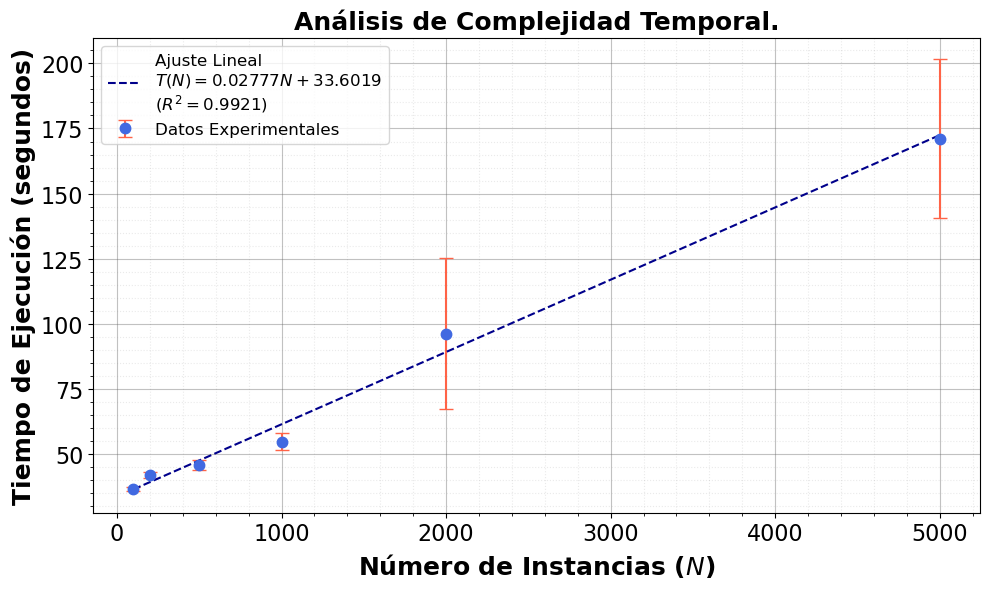

Ecuación reportada: $T(N) = 0.02777N +33.6019$


In [10]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# 1. Cargar datos
with open('experimento_scaleup_wrapper_lgbm.pkl', 'rb') as f:
    historial = pickle.load(f)

# 2. Procesar datos
x_avg = sorted(historial.keys())
y_avg = []
y_std = []

for N in x_avg:
    tiempos = [run['tiempo'] for run in historial[N]]
    y_avg.append(np.mean(tiempos))
    y_std.append(np.std(tiempos))

x_avg = np.array(x_avg)
y_avg = np.array(y_avg)

# 3. Ajuste Lineal
coef = np.polyfit(x_avg, y_avg, 1)
y_pred = np.polyval(coef, x_avg)
r2 = r2_score(y_avg, y_pred)

# --- CREAMOS EL TEXTO DE LA ECUACIÓN ---
# coef[0] es la pendiente (m), coef[1] es la intersección (b)
ecuacion_str = f'$T(N) = {coef[0]:.5f}N {coef[1]:+.4f}$'
label_ajuste = f'Ajuste Lineal\n{ecuacion_str}\n($R^2 = {r2:.4f}$)'

# 4. Graficación
plt.figure(figsize=(10, 6))

# Puntos Experimentales
plt.errorbar(x_avg, y_avg, yerr=y_std, fmt='o', color='royalblue', 
             ecolor='tomato', capsize=5, label='Datos Experimentales', markersize=7.5)

# Línea de Ajuste (Recta)
x_range = np.linspace(min(x_avg), max(x_avg), 100)
plt.plot(x_range, np.polyval(coef, x_range), color='darkblue', linestyle='--', 
         label=label_ajuste)  # <--- Aquí ponemos la ecuación en la leyenda

# Opcional: Si prefieres la ecuación flotando en el gráfico en lugar de la leyenda:
# plt.text(0.05, 0.85, ecuacion_str + f'\n$R^2 = {r2:.4f}$', 
#          transform=plt.gca().transAxes, fontsize=12, 
#          bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'))

plt.title('Análisis de Complejidad Temporal.', fontsize=18, fontweight= 'bold')
plt.xlabel('Número de Instancias ($N$)', fontsize=18, fontweight= 'bold')
plt.ylabel('Tiempo de Ejecución (segundos)', fontsize=18, fontweight = 'bold')
plt.legend(loc='upper left', fontsize=12) # Ubicación de la leyenda
plt.grid(True, linestyle=':', alpha=0.6)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# 1. Activamos los "ticks" menores (divisiones pequeñas)
plt.minorticks_on()

# 2. Configuramos la Cuadrícula Mayor (Líneas principales)
plt.grid(visible=True, which='major', color='#666666', linestyle='-', alpha=0.4)

# 3. Configuramos la Cuadrícula Menor (Líneas detalladas)
plt.grid(visible=True, which='minor', color='#999999', linestyle=':', alpha=0.2)

# ---------------------------------------------------

plt.tight_layout()
plt.show()

print(f"Ecuación reportada: {ecuacion_str}")

In [11]:
#Tiempo para N instanciasWRAPPED
N = 100000 #Numero de instancias
tiempo= 0.02777 * (N) + 33.6019

print(f"Segundos: {tiempo}")
print(f"Minutos: {tiempo/60}")
print(f"Horas: {(tiempo/60)/60}")
print(f"Dias: {((tiempo/60)/60)/24}")

Segundos: 2810.6019
Minutos: 46.843365
Horas: 0.78072275
Dias: 0.03253011458333333


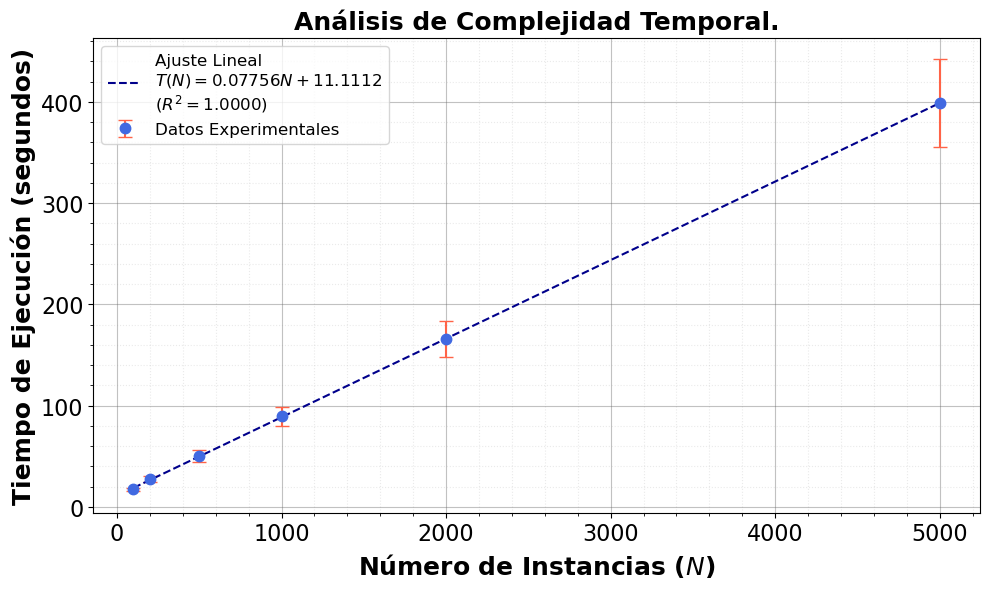

Ecuación reportada: $T(N) = 0.07756N +11.1112$


In [12]:
#TASA DE INCONSISTENCIA Y UNICIDAD
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# 1. Cargar datos
with open('experimento6_escalabilidad_soluciones_paralelizado_inconsistenciaYUnicidad.pkl', 'rb') as f:
    historial = pickle.load(f)

# 2. Procesar datos
x_avg = sorted(historial.keys())
y_avg = []
y_std = []

for N in x_avg:
    tiempos = [run['tiempo'] for run in historial[N]]
    y_avg.append(np.mean(tiempos))
    y_std.append(np.std(tiempos))

x_avg = np.array(x_avg)
y_avg = np.array(y_avg)

# 3. Ajuste Lineal
coef = np.polyfit(x_avg, y_avg, 1)
y_pred = np.polyval(coef, x_avg)
r2 = r2_score(y_avg, y_pred)

# --- CREAMOS EL TEXTO DE LA ECUACIÓN ---
# coef[0] es la pendiente (m), coef[1] es la intersección (b)
ecuacion_str = f'$T(N) = {coef[0]:.5f}N {coef[1]:+.4f}$'
label_ajuste = f'Ajuste Lineal\n{ecuacion_str}\n($R^2 = {r2:.4f}$)'

# 4. Graficación
plt.figure(figsize=(10, 6))

# Puntos Experimentales
plt.errorbar(x_avg, y_avg, yerr=y_std, fmt='o', color='royalblue', 
             ecolor='tomato', capsize=5, label='Datos Experimentales', markersize=7.5)

# Línea de Ajuste (Recta)
x_range = np.linspace(min(x_avg), max(x_avg), 100)
plt.plot(x_range, np.polyval(coef, x_range), color='darkblue', linestyle='--', 
         label=label_ajuste)  # <--- Aquí ponemos la ecuación en la leyenda

# Opcional: Si prefieres la ecuación flotando en el gráfico en lugar de la leyenda:
# plt.text(0.05, 0.85, ecuacion_str + f'\n$R^2 = {r2:.4f}$', 
#          transform=plt.gca().transAxes, fontsize=12, 
#          bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'))

plt.title('Análisis de Complejidad Temporal.', fontsize=18, fontweight= 'bold')
plt.xlabel('Número de Instancias ($N$)', fontsize=18, fontweight= 'bold')
plt.ylabel('Tiempo de Ejecución (segundos)', fontsize=18, fontweight = 'bold')
plt.legend(loc='upper left', fontsize=12) # Ubicación de la leyenda
plt.grid(True, linestyle=':', alpha=0.6)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# 1. Activamos los "ticks" menores (divisiones pequeñas)
plt.minorticks_on()

# 2. Configuramos la Cuadrícula Mayor (Líneas principales)
plt.grid(visible=True, which='major', color='#666666', linestyle='-', alpha=0.4)

# 3. Configuramos la Cuadrícula Menor (Líneas detalladas)
plt.grid(visible=True, which='minor', color='#999999', linestyle=':', alpha=0.2)

# ---------------------------------------------------

plt.tight_layout()
plt.show()

print(f"Ecuación reportada: {ecuacion_str}")

In [13]:
#Tiempo para N inconsistencia unicidad
N = 10000 #Numero de instancias
tiempo= 0.07756 * (N) + 11.1112

print(f"Segundos: {tiempo}")
print(f"Minutos: {tiempo/60}")
print(f"Horas: {(tiempo/60)/60}")
print(f"Dias: {((tiempo/60)/60)/24}")

Segundos: 786.7112000000001
Minutos: 13.111853333333334
Horas: 0.2185308888888889
Dias: 0.009105453703703704


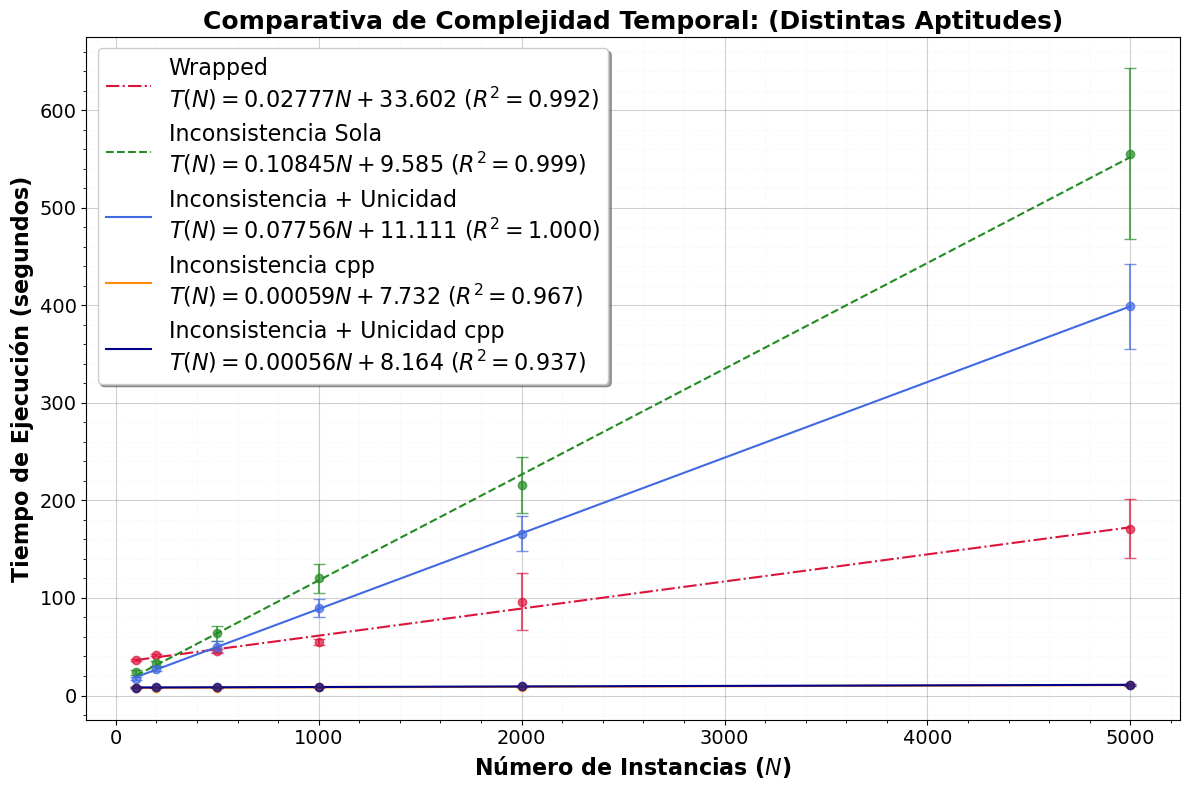

In [ ]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# Nombres de los archivos
archivos = {
    'Wrapped': 'experimento_scaleup_wrapper_lgbm.pkl',
    'Inconsistencia Sola': 'experimento5_escalabilidad_soluciones_paralelizado.pkl',
    'Inconsistencia + Unicidad': 'experimento6_escalabilidad_soluciones_paralelizado_inconsistenciaYUnicidad.pkl',
    'Inconsistencia cpp': 'experimento7_escalabilidad_soluciones_paralelizado_inconsistencia_cpp.pkl',
    'Inconsistencia + Unicidad cpp': 'experimento8_escalabilidad_soluciones_paralelizado_inconsistencia_unicidad_cpp.pkl'

}

colores = {'Wrapped': 'crimson', 'Inconsistencia Sola': 'forestgreen', 'Inconsistencia + Unicidad': 'royalblue', 'Inconsistencia cpp': 'darkorange', 'Inconsistencia + Unicidad cpp': 'darkblue'}
estilos = {'Wrapped': '-.', 'Inconsistencia Sola': '--', 'Inconsistencia + Unicidad': '-', 'Inconsistencia cpp': '-', 'Inconsistencia + Unicidad cpp': '-'}

plt.figure(figsize=(12, 8))

# 2. Procesar y Graficar cada experimento
for nombre, ruta in archivos.items():
    try:
        with open(ruta, 'rb') as f:
            historial = pickle.load(f)
        
        x_n = sorted(historial.keys())
        y_avg = []
        y_std = []

        for N in x_n:
            tiempos = [run['tiempo'] for run in historial[N]]
            y_avg.append(np.mean(tiempos))
            y_std.append(np.std(tiempos))

        x_n = np.array(x_n)
        y_avg = np.array(y_avg)

        # Ajuste Lineal
        coef = np.polyfit(x_n, y_avg, 1)
        y_pred = np.polyval(coef, x_n)
        r2 = r2_score(y_avg, y_pred)

        # Etiqueta con Ecuación para la leyenda
        ecuacion = f'$T(N) = {coef[0]:.5f}N {coef[1]:+.3f}$ ($R^2={r2:.3f}$)'
        
        # Dibujar Puntos con barras de error
        plt.errorbar(x_n, y_avg, yerr=y_std, fmt='o', color=colores[nombre], 
                     ecolor=colores[nombre], capsize=4, alpha=0.7, markersize=6)

        # Dibujar Línea de Ajuste
        x_range = np.linspace(min(x_n), max(x_n), 100)
        plt.plot(x_range, np.polyval(coef, x_range), color=colores[nombre], 
                 linestyle=estilos[nombre], label=f'{nombre}\n{ecuacion}')

    except FileNotFoundError:
        print(f"Advertencia: No se encontró el archivo {ruta}")

# 3. Configuración de la Gráfica
plt.title('Comparativa de Complejidad Temporal: (Distintas Aptitudes)', fontsize=18, fontweight='bold')
plt.xlabel('Número de Instancias ($N$)', fontsize=16, fontweight='bold')
plt.ylabel('Tiempo de Ejecución (segundos)', fontsize=16, fontweight='bold')

plt.legend(loc='upper left', fontsize=16, frameon=True, shadow=True)
plt.grid(True, which='major', color='#666666', linestyle='-', alpha=0.3)
plt.grid(True, which='minor', color='#999999', linestyle=':', alpha=0.1)
plt.minorticks_on()

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.tight_layout()
plt.show()

In [2]:
#CALCULO DEL TIEMPO PARA EL METODO WRAPPED
N=100000
tiempo = 0.02777 * N +33.602

print(f"Segundos: {tiempo}")
print(f"Minutos: {tiempo/60}")
print(f"Horas: {(tiempo/60)/60}")
print(f"Dias: {((tiempo/60)/60)/24}")

Segundos: 2810.602
Minutos: 46.84336666666666
Horas: 0.7807227777777777
Dias: 0.03253011574074074


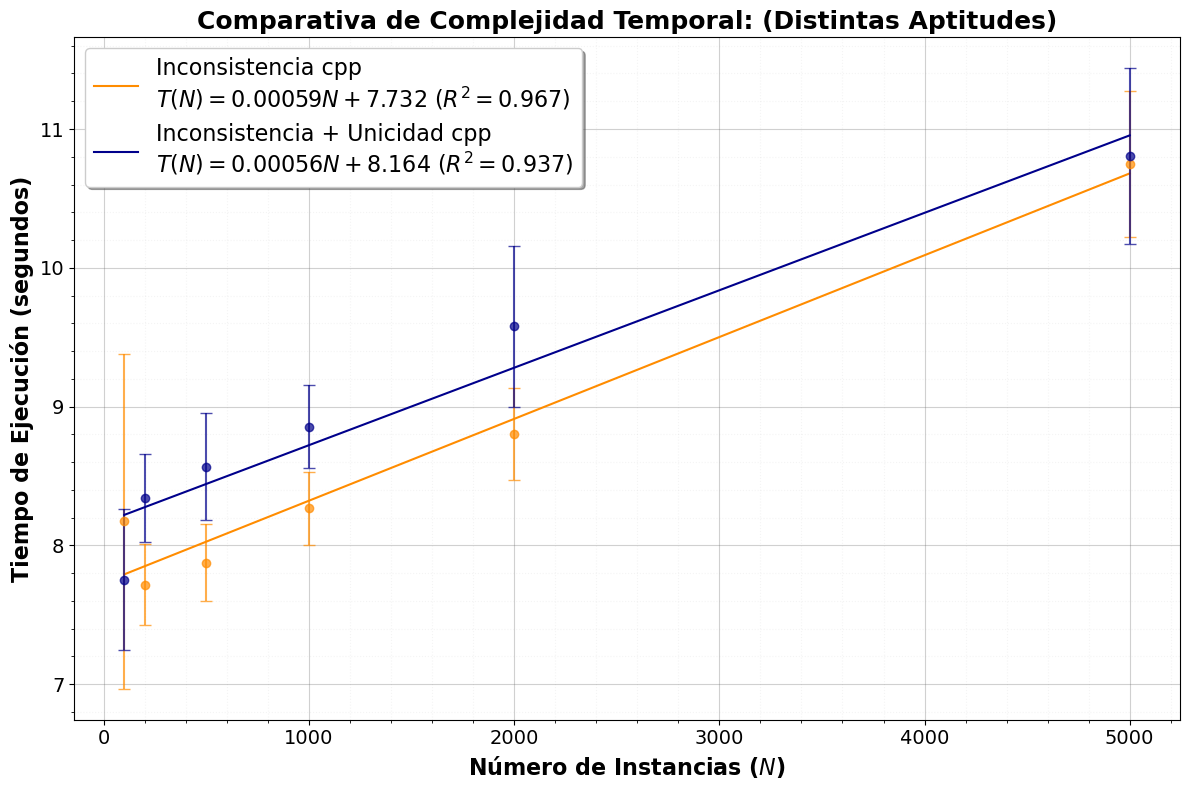

In [16]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# Nombres de los archivos
archivos = {
    'Inconsistencia cpp': 'experimento7_escalabilidad_soluciones_paralelizado_inconsistencia_cpp.pkl',
    'Inconsistencia + Unicidad cpp': 'experimento8_escalabilidad_soluciones_paralelizado_inconsistencia_unicidad_cpp.pkl'
}

colores = {'Inconsistencia cpp': 'darkorange', 'Inconsistencia + Unicidad cpp': 'darkblue'}
estilos = {'Inconsistencia cpp': '-', 'Inconsistencia + Unicidad cpp': '-'}

plt.figure(figsize=(12, 8))

# 2. Procesar y Graficar cada experimento
for nombre, ruta in archivos.items():
    try:
        with open(ruta, 'rb') as f:
            historial = pickle.load(f)
        
        x_n = sorted(historial.keys())
        y_avg = []
        y_std = []

        for N in x_n:
            tiempos = [run['tiempo'] for run in historial[N]]
            y_avg.append(np.mean(tiempos))
            y_std.append(np.std(tiempos))

        x_n = np.array(x_n)
        y_avg = np.array(y_avg)

        # Ajuste Lineal
        coef = np.polyfit(x_n, y_avg, 1)
        y_pred = np.polyval(coef, x_n)
        r2 = r2_score(y_avg, y_pred)

        # Etiqueta con Ecuación para la leyenda
        ecuacion = f'$T(N) = {coef[0]:.5f}N {coef[1]:+.3f}$ ($R^2={r2:.3f}$)'
        
        # Dibujar Puntos con barras de error
        plt.errorbar(x_n, y_avg, yerr=y_std, fmt='o', color=colores[nombre], 
                     ecolor=colores[nombre], capsize=4, alpha=0.7, markersize=6)

        # Dibujar Línea de Ajuste
        x_range = np.linspace(min(x_n), max(x_n), 100)
        plt.plot(x_range, np.polyval(coef, x_range), color=colores[nombre], 
                 linestyle=estilos[nombre], label=f'{nombre}\n{ecuacion}')

    except FileNotFoundError:
        print(f"Advertencia: No se encontró el archivo {ruta}")

# 3. Configuración de la Gráfica
plt.title('Comparativa de Complejidad Temporal: (Distintas Aptitudes)', fontsize=18, fontweight='bold')
plt.xlabel('Número de Instancias ($N$)', fontsize=16, fontweight='bold')
plt.ylabel('Tiempo de Ejecución (segundos)', fontsize=16, fontweight='bold')

plt.legend(loc='upper left', fontsize=16, frameon=True, shadow=True)
plt.grid(True, which='major', color='#666666', linestyle='-', alpha=0.3)
plt.grid(True, which='minor', color='#999999', linestyle=':', alpha=0.1)
plt.minorticks_on()

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.tight_layout()
plt.show()

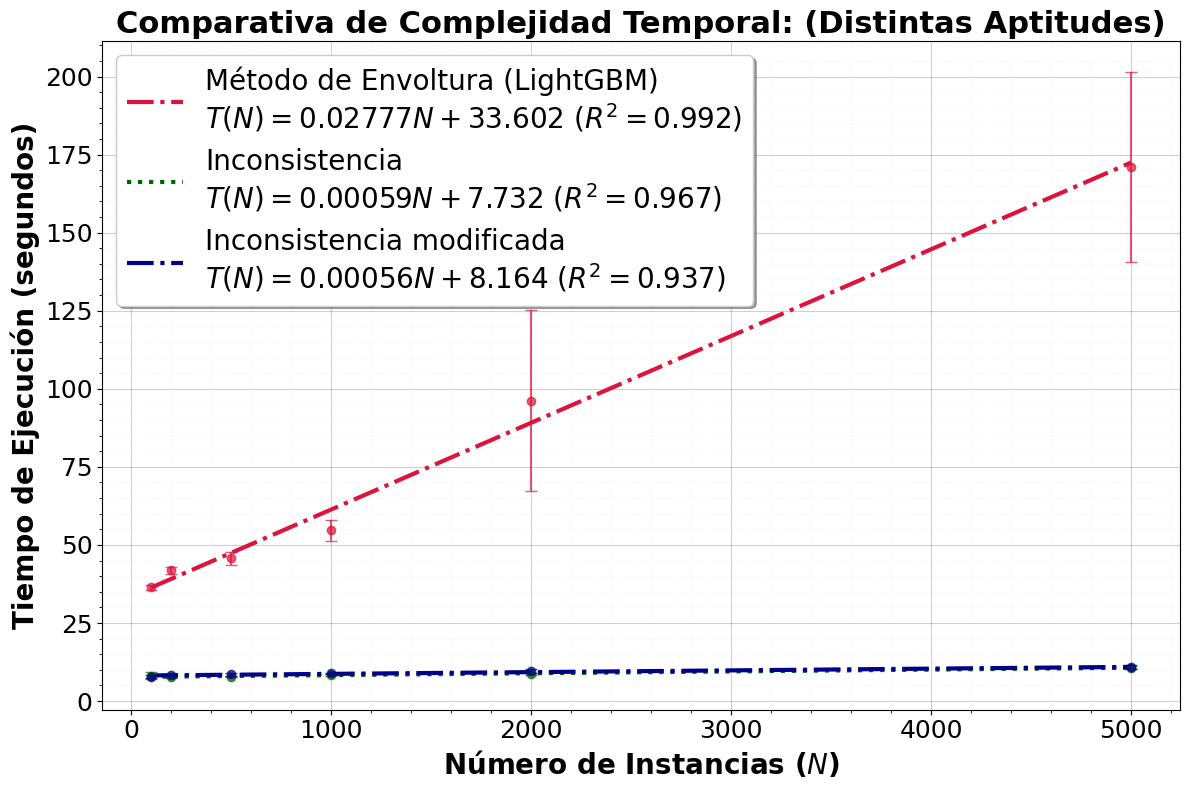

In [9]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# Nombres de los archivos
archivos = {
    'Método de Envoltura (LightGBM)': 'experimento_scaleup_wrapper_lgbm.pkl',
    #'Inconsistencia Sola': 'experimento5_escalabilidad_soluciones_paralelizado.pkl',
    #'Inconsistencia + Unicidad': 'experimento6_escalabilidad_soluciones_paralelizado_inconsistenciaYUnicidad.pkl',
    'Inconsistencia': 'experimento7_escalabilidad_soluciones_paralelizado_inconsistencia_cpp.pkl',
    'Inconsistencia modificada': 'experimento8_escalabilidad_soluciones_paralelizado_inconsistencia_unicidad_cpp.pkl'

}

colores = {'Método de Envoltura (LightGBM)': 'crimson', 'Inconsistencia': 'darkgreen', 'Inconsistencia modificada': 'darkblue'}
estilos = {'Método de Envoltura (LightGBM)': '-.', 'Inconsistencia': ':', 'Inconsistencia modificada': '-.'}

plt.figure(figsize=(12, 8))

# 2. Procesar y Graficar cada experimento
for nombre, ruta in archivos.items():
    try:
        with open(ruta, 'rb') as f:
            historial = pickle.load(f)
        
        x_n = sorted(historial.keys())
        y_avg = []
        y_std = []

        for N in x_n:
            tiempos = [run['tiempo'] for run in historial[N]]
            y_avg.append(np.mean(tiempos))
            y_std.append(np.std(tiempos))

        x_n = np.array(x_n)
        y_avg = np.array(y_avg)

        # Ajuste Lineal
        coef = np.polyfit(x_n, y_avg, 1)
        y_pred = np.polyval(coef, x_n)
        r2 = r2_score(y_avg, y_pred)

        # Etiqueta con Ecuación para la leyenda
        ecuacion = f'$T(N) = {coef[0]:.5f}N {coef[1]:+.3f}$ ($R^2={r2:.3f}$)'
        
        # Dibujar Puntos con barras de error
        plt.errorbar(x_n, y_avg, yerr=y_std, fmt='o', color=colores[nombre], 
                     ecolor=colores[nombre], capsize=4, alpha=0.7, markersize=6)

        # Dibujar Línea de Ajuste
        x_range = np.linspace(min(x_n), max(x_n), 100)
        plt.plot(x_range, np.polyval(coef, x_range), color=colores[nombre], 
                 linestyle=estilos[nombre], linewidth=3 , label=f'{nombre}\n{ecuacion}')

    except FileNotFoundError:
        print(f"Advertencia: No se encontró el archivo {ruta}")

# 3. Configuración de la Gráfica
plt.title('Comparativa de Complejidad Temporal: (Distintas Aptitudes)', fontsize=22, fontweight='bold')
plt.xlabel('Número de Instancias ($N$)', fontsize=20, fontweight='bold')
plt.ylabel('Tiempo de Ejecución (segundos)', fontsize=20, fontweight='bold')

plt.legend(loc='upper left', fontsize=20, frameon=True, shadow=True)
plt.grid(True, which='major', color='#666666', linestyle='-', alpha=0.3)
plt.grid(True, which='minor', color='#999999', linestyle=':', alpha=0.1)
plt.minorticks_on()

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.tight_layout()
plt.show()

In [ ]:
0